# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: Gate 2 GO / Gate 3 NA — non-branching — so 04_correlation and 05_modules are
not produced; the unconditional EMT-TF step becomes notebook 04.)*

Score a wide EMT-TF panel (Snail/Zeb/Twist **plus** the FOXC and PRRX mesenchymal families — 03_eval
fork 5) gated on detectable expression, and read which factors mark the root vs the terminus.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import warnings; warnings.filterwarnings('ignore')
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold (keeps the house linear layout)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 1091 | pseudotime 0.0 -> 19.61


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing, mean in the early (root) vs late (terminus)
pseudotime tercile, and Spearman rho vs pseudotime. Among detectably-expressed factors
(`frac_expr > 0.03`), take the most root-end (lowest rho) and most terminus-end (highest rho).

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.033       0.055      0.061     0.037 LATE(terminus)
 SNAI1      0.045       0.069      0.111     0.079 LATE(terminus)
 SNAI2      0.052       0.056      0.143     0.106 LATE(terminus)
TWIST1      0.184       0.180      0.429     0.190 LATE(terminus)
  ZEB2      0.507       0.655      1.207     0.211 LATE(terminus)
  ZEB1      0.393       0.462      1.135     0.278 LATE(terminus)
 PRRX1      0.405       0.353      1.125     0.344 LATE(terminus)

derived pair: FOXC1 (early/root) <-> PRRX1 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, **categorical overlay** of thresholded
expressers (upper quartile among expressing cells) on a grey manifold — not a continuous colormap
(04_test Sun2021 BINDING note).

FOXC1: 3.3% expressing; 9 shown (upper quartile), mean pt of shown = 0.32 (all = 0.55)
PRRX1: 40.5% expressing; 111 shown (upper quartile), mean pt of shown = 0.63 (all = 0.55)
saved expression.pdf


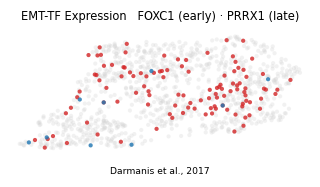

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')